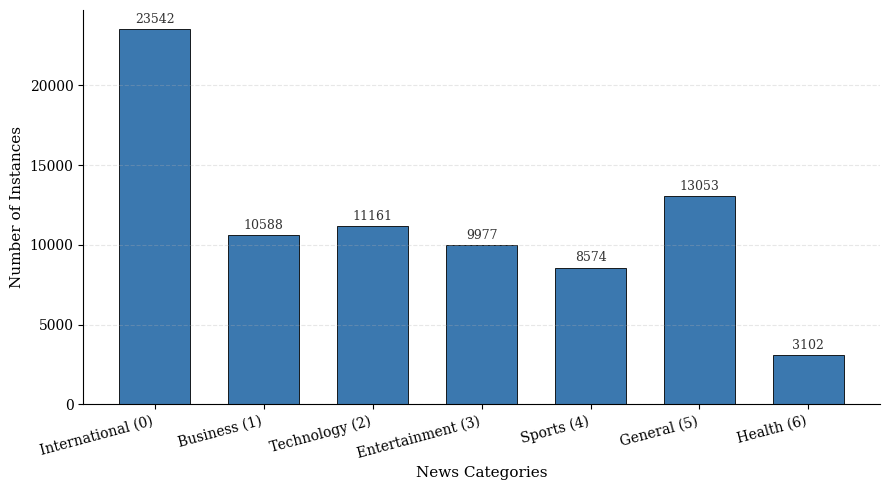

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Caricamento e mappatura delle classi
df = pd.read_csv('development.csv')

class_map = {
    0: "International",
    1: "Business",
    2: "Technology",
    3: "Entertainment",
    4: "Sports",
    5: "General",
    6: "Health"
}

# Calcolo frequenze e rinomina indici
class_dist = df['label'].value_counts().sort_index()
class_names = [f"{class_map[i]} ({i})" for i in class_dist.index]

# 2. Setup grafico (Stile "Example Project")
plt.figure(figsize=(9, 5))
plt.rcParams['font.family'] = 'serif'

# Creazione barre in "Academic Blue"
bars = plt.bar(class_names, class_dist.values, 
               color= '#3B78AF',      # Blu simile all'esempio
               edgecolor='black', 
               linewidth=0.6,
               width=0.65)

# 3. Estetica e Labels
plt.ylabel('Number of Instances', fontsize=11)
plt.xlabel('News Categories', fontsize=11)

# Rotazione etichette per evitare sovrapposizioni se necessario
plt.xticks(rotation=15, ha='right', fontsize=10)

# Griglia solo orizzontale puntinata (molto discreta)
plt.grid(axis='y', linestyle='--', alpha=0.3)

# Rimuovi i bordi "superflui" per pulizia
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 4. Annotazione (opzionale: mostra il numero esatto sopra ogni barra)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 200, yval, 
             ha='center', va='bottom', fontsize=9, color='#333333')

plt.tight_layout()
plt.savefig('class_distribution_blue.png')
plt.show()

In [4]:
counts = df['label'].value_counts()

# Calcoli statistici
mean_val = counts.mean()
std_val = counts.std()
var_val = counts.var()
cv_val = std_val / mean_val  # Coefficiente di Variazione
imbalance_ratio = counts.max() / counts.min()

print(f"Mean samples per class: {mean_val:.2f}")
print(f"Variance: {var_val:.2f}")
print(f"Coefficient of Variation: {cv_val:.4f}")
print(f"Imbalance Ratio (Max/Min): {imbalance_ratio:.2f}")

Mean samples per class: 11428.14
Variance: 38289917.14
Coefficient of Variation: 0.5415
Imbalance Ratio (Max/Min): 7.59


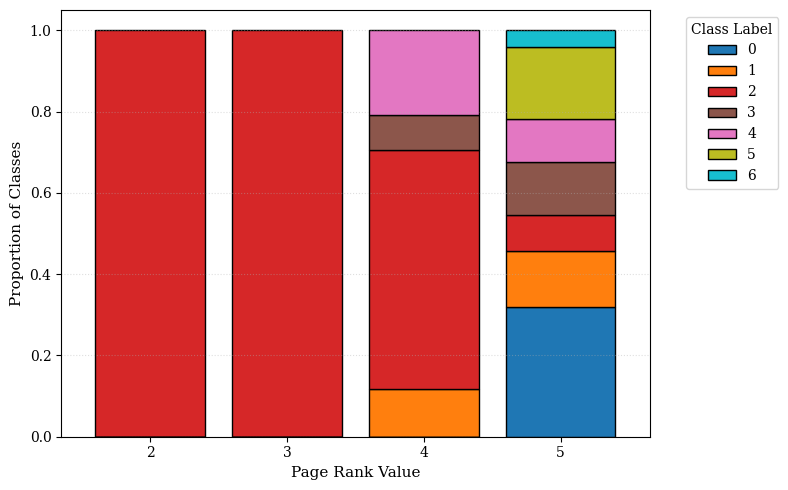

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Caricamento
df = pd.read_csv('development.csv')

# Creiamo una Cross-Tabulation (Tabella a doppia entrata)
# Normalizziamo per riga ('index') per vedere le percentuali
ct = pd.crosstab(df['page_rank'], df['label'], normalize='index')

# Setup Grafico
plt.figure(figsize=(8, 5))
plt.rcParams['font.family'] = 'serif'

# Stacked Bar Plot
# Usa una colormap che distingua bene le 7 classi (es. 'tab10' o 'Set2')
ct.plot(kind='bar', stacked=True, colormap='tab10', edgecolor='black', width=0.8, ax=plt.gca(), rot=0)

plt.xlabel('Page Rank Value', fontsize=11)
plt.ylabel('Proportion of Classes', fontsize=11)
plt.legend(title='Class Label', bbox_to_anchor=(1.05, 1), loc='upper left')

# Pulizia
plt.tight_layout()
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.savefig('pagerank_analysis.png')
plt.show()

In [6]:
print(len(df["source"].unique())) 

1359


In [7]:
# Identificazione dei duplicati (tranne id)
columns_to_check = [col for col in df.columns if col in ['article']]
duplicates = df.duplicated(subset=columns_to_check, keep='first')
num_duplicates = duplicates.sum()
print(f"Numero di righe duplicate rilevate: {num_duplicates}")

# Identificazione dei duplicati (tranne id e label)
columns_to_check = [col for col in df.columns if col not in ['Id', 'label']]
duplicates = df.duplicated(subset=columns_to_check, keep='first')
num_duplicates = duplicates.sum()
print(f"Numero di righe duplicate rilevate: {num_duplicates}")

# Identificazione dei duplicati (uguale title article)
columns_to_check = [col for col in df.columns if col in ['label','article']]
duplicates = df.duplicated(subset=columns_to_check, keep='first')
num_duplicates = duplicates.sum()
print(f"Numero di righe duplicate rilevate: {num_duplicates}")

# Identificazione dei duplicati (uguale source article)
columns_to_check = [col for col in df.columns if col in ['source','article','label']]
duplicates = df.duplicated(subset=columns_to_check, keep='first')
num_duplicates = duplicates.sum()
print(f"Numero di righe duplicate rilevate: {num_duplicates}")

# Identificazione dei duplicati (uguale title source)
columns_to_check = [col for col in df.columns if col in ['title','source']]
duplicates = df.duplicated(subset=columns_to_check, keep='first')
num_duplicates = duplicates.sum()
print(f"Numero di righe duplicate rilevate: {num_duplicates}")


Numero di righe duplicate rilevate: 5603
Numero di righe duplicate rilevate: 818
Numero di righe duplicate rilevate: 3951
Numero di righe duplicate rilevate: 3870
Numero di righe duplicate rilevate: 3974


In [13]:
print(df[df['title']=="\\N"])

Empty DataFrame
Columns: [Id, source, title, article, page_rank, timestamp, label]
Index: []


In [9]:
# Definiamo le colonne che identificano il "contenuto" della notizia
content_cols = ['title', 'article','label']

# Raggruppiamo per contenuto e contiamo le occorrenze
group_counts = df.groupby(content_cols).size()

# Filtriamo solo i gruppi che hanno almeno un duplicato
duplicates_counts = group_counts[group_counts > 1]

# 1. Analisi delle COPPIE (esattamente 2 occorrenze)
pairs = duplicates_counts[duplicates_counts == 2]
print(f"Gruppi composti da una coppia: {len(pairs)}")
print(f"Totale righe coinvolte in coppie: {len(pairs) * 2}")

# 2. Analisi dei gruppi con PIÙ DI 2 occorrenze
multiple = duplicates_counts[duplicates_counts > 2]
print(f"\nGruppi con più di 2 occorrenze: {len(multiple)}")
print(f"Totale righe coinvolte in questi gruppi: {multiple.sum()}")

# 3. Distribuzione delle frequenze (quanti gruppi da 3, da 4, ecc.)
print("\nDistribuzione grandezza gruppi (> 2):")
print(multiple.value_counts().sort_index())

# 4. ISPEZIONE: Vediamo il contenuto del gruppo più frequente
top_content = duplicates_counts.idxmax() # Trova il titolo/articolo più ripetuto
max_occurrences = duplicates_counts.max()

print(f"\n--- ESEMPIO CONTENUTO PIÙ FREQUENTE ({max_occurrences} volte) ---")
print(f"TITOLO: {top_content[0]}")
print(f"ARTICOLO (estratto): {top_content[1][:200]}...")

Gruppi composti da una coppia: 1039
Totale righe coinvolte in coppie: 2078

Gruppi con più di 2 occorrenze: 106
Totale righe coinvolte in questi gruppi: 477

Distribuzione grandezza gruppi (> 2):
3     61
4     15
5     12
6      6
7      3
8      1
9      1
11     3
12     1
17     1
19     2
Name: count, dtype: int64

--- ESEMPIO CONTENUTO PIÙ FREQUENTE (19 volte) ---
TITOLO: ADV: Distance Learning Directory - Online Degrees
ARTICOLO (estratto): Bachelor, Master and Post-Grad degrees online from accredited colleges and universities. Business, Education, IT, Healthcare, more. Browse by degree or program. Request info and get started today....
